# Chapter 20: ODE, SDE, and Continuous Limits of Algorithms
## Interactive Python & PyTorch Companion Notebook

Welcome to the companion coding notebook for **Chapter 20: ODE, SDE, and Continuous Limits of Algorithms**. In this notebook, we verify all six exercise modules from `exercises/math.md` through analytical checks and numerical simulations:

1. **Exercise 1 (Discrete to Continuous Limits):** Comparing discrete Gradient Descent updates $\mathbf{x}_{k+1} = \mathbf{x}_k - \eta \nabla f(\mathbf{x}_k)$ against the continuous Gradient Flow ODE $\dot{\mathbf{x}}(t) = -\nabla f(\mathbf{x}(t))$, and the step-size window $0 < \eta < 2/\lambda$ of gradient descent on a quadratic.
2. **Exercises 2 & 3 (Probability Flow ODE & Continuity Equation):** Verifying that the Probability Flow ODE $\dot{\mathbf{x}} = \mathbf{f}(\mathbf{x}, t) - \frac{1}{2}\mathbf{a}(t)\nabla_{\mathbf{x}}\log p_t(\mathbf{x})$ and the 1D Continuity Equation $\partial_t p_t + \partial_x(p_t v_t) = 0$ conserve total probability mass $\int p_t(x)\,dx = 1$, the contracting flow $p_t = \mathcal{N}(0, e^{-2t})$ of Exercise 3, and match the exact marginal densities of the stochastic SDE.
3. **Exercise 4 (Conditional Flow Matching):** Training a PyTorch velocity network $v_\theta(x, t)$ using the Optimal Transport Conditional Flow Matching (CFM) objective $\mathcal{L}_{\mathrm{CFM}}(\theta) = \mathbb{E}\|v_\theta(x_t, t) - (x_1 - x_0)\|_2^2$ and generating samples with a deterministic Euler ODE solver.
4. **Exercises 5 & 6 (State-Space Models as Flows & ODE vs SDE Tradeoffs):** Analyzing Hurwitz eigenvalue stability $\operatorname{Re}(\lambda_i(A)) < 0$, comparing Forward Euler ($\bar{A} = I + \Delta t A$) against Zero-Order Hold ($\bar{A} = \exp(\Delta t A)$) discretization, and contrasting smooth non-crossing ODE streamlines with stochastic SDE sample paths.

In [1]:
import numpy as np
import scipy.linalg as la
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 10,
})

np.random.seed(42)
torch.manual_seed(42)
print("Environment initialized successfully.")

Environment initialized successfully.


---
## 1. Exercise 1: Discrete to Continuous Limits (Gradient Flow & Step-Size Stability)

### 1.1 Gradient Descent to Gradient Flow ODE
Starting from $\mathbf{x}_{k+1} = \mathbf{x}_k - \eta \nabla f(\mathbf{x}_k)$, identify continuous time $t = k\eta$ and write $\mathbf{x}(t) \approx \mathbf{x}_k$:
$$\frac{\mathbf{x}(t + \eta) - \mathbf{x}(t)}{\eta} = -\nabla f(\mathbf{x}(t)) \xrightarrow{\eta \to 0} \frac{d\mathbf{x}(t)}{dt} = -\nabla f(\mathbf{x}(t)).$$
For an anisotropic quadratic objective $f(x_1, x_2) = \frac{1}{2}(\lambda_1 x_1^2 + \lambda_2 x_2^2)$, the exact continuous trajectory is $\mathbf{x}(t) = (x_1(0)e^{-\lambda_1 t},\, x_2(0)e^{-\lambda_2 t})$.

### 1.2 Gradient Descent versus Gradient Flow on a Quadratic
For $f(x) = \frac{\lambda}{2}x^2$, gradient descent gives $x_k = (1 - \eta\lambda)^k x_0$ and the flow gives $x(t) = x_0e^{-\lambda t}$. With $t = k\eta$ the iterates follow the flow as $\eta \to 0$, but they converge only for $0 < \eta < 2/\lambda$ and alternate in sign for $\eta > 1/\lambda$.


In [2]:
# Exercise 1.2 and Exercise 3: closed forms checked numerically
lam_q, x0_q = 2.0, 1.0
for eta_q in (0.01, 0.4, 0.9, 1.05):
    k_q = int(round(1.0 / eta_q)) if eta_q < 0.5 else 20
    x_k = (1 - eta_q * lam_q) ** k_q * x0_q
    print(f"[Ex 1.2] eta={eta_q:4.2f}: x_k after {k_q:3d} steps = {x_k:+.4f}"
          + (f"  (flow at t={k_q * eta_q:.2f}: {x0_q * np.exp(-lam_q * k_q * eta_q):.4f})" if eta_q < 0.5 else "")
          + ("  -> diverges, eta > 2/lambda" if eta_q > 2 / lam_q else ""))
rng_c = np.random.default_rng(3)
t_c = 0.7
X_t = np.exp(-t_c) * rng_c.standard_normal(2_000_000)          # X_t = e^{-t} X_0
print(f"[Ex 3.3] Var(X_t) = {X_t.var():.4f}  (e^(-2t) = {np.exp(-2 * t_c):.4f})")
xx = np.linspace(-1.5, 1.5, 7); h = 1e-4
p_c = lambda x, t: np.exp(t) / np.sqrt(2 * np.pi) * np.exp(-np.exp(2 * t) * x**2 / 2)
lhs = (p_c(xx, t_c + h) - p_c(xx, t_c - h)) / (2 * h)
rhs = ((xx + h) * p_c(xx + h, t_c) - (xx - h) * p_c(xx - h, t_c)) / (2 * h)
print(f"[Ex 3.3] max |d_t p - d_x(x p)| on a grid = {np.max(np.abs(lhs - rhs)):.1e}")


[Ex 1.2] eta=0.01: x_k after 100 steps = +0.1326  (flow at t=1.00: 0.1353)
[Ex 1.2] eta=0.40: x_k after   2 steps = +0.0400  (flow at t=0.80: 0.2019)
[Ex 1.2] eta=0.90: x_k after  20 steps = +0.0115
[Ex 1.2] eta=1.05: x_k after  20 steps = +6.7275  -> diverges, eta > 2/lambda
[Ex 3.3] Var(X_t) = 0.2464  (e^(-2t) = 0.2466)
[Ex 3.3] max |d_t p - d_x(x p)| on a grid = 1.8e-08


Step size eta = 0.160 | Max trajectory error ||x_k - x(k*eta)||_2 = 1.48958
Step size eta = 0.040 | Max trajectory error ||x_k - x(k*eta)||_2 = 0.17049
Step size eta = 0.010 | Max trajectory error ||x_k - x(k*eta)||_2 = 0.03788


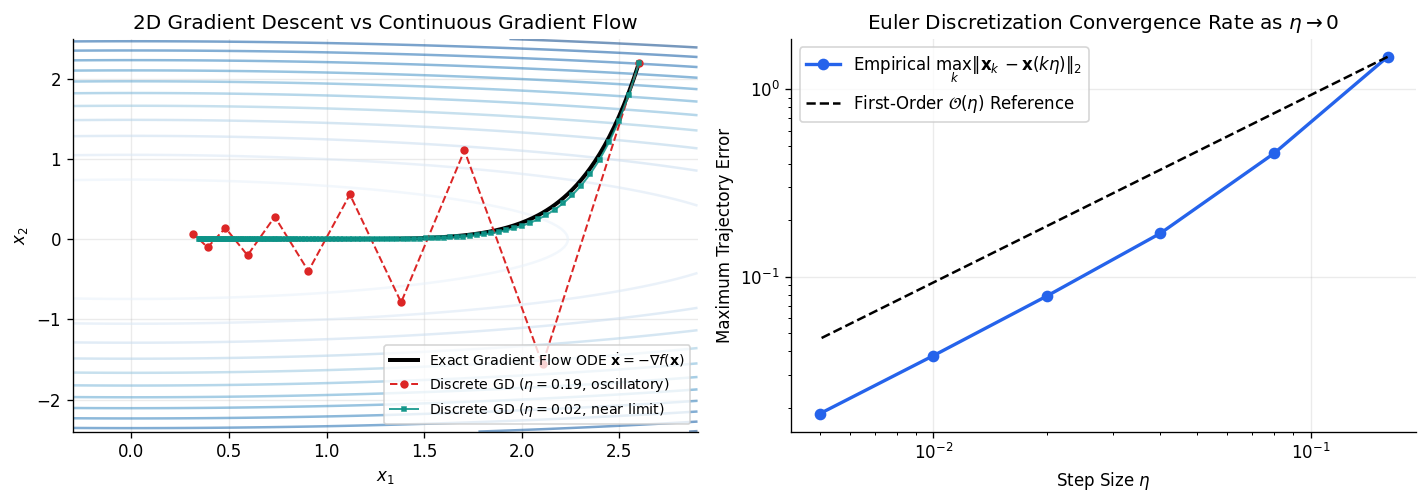

In [3]:
# Anisotropic quadratic bowl: f(x1, x2) = 0.5 * (lam1 * x1^2 + lam2 * x2^2)
lam = np.array([1.0, 9.0])
x0 = np.array([2.6, 2.2])
T_gd = 2.0
t_cont = np.linspace(0.0, T_gd, 400)

# Exact Gradient Flow ODE trajectory
x_ode = x0[None, :] * np.exp(-t_cont[:, None] * lam[None, :])

def run_discrete_gd(eta, T_max):
    n_steps = int(T_max / eta)
    traj = np.zeros((n_steps + 1, 2))
    traj[0] = x0
    for k in range(n_steps):
        traj[k + 1] = traj[k] - eta * (lam * traj[k])
    return traj

traj_large = run_discrete_gd(0.19, T_gd)
traj_med = run_discrete_gd(0.08, T_gd)
traj_small = run_discrete_gd(0.02, T_gd)

# Quantify global sup-norm error vs step size eta
etas_test = np.array([0.16, 0.08, 0.04, 0.02, 0.01, 0.005])
max_errors = []
for eta in etas_test:
    tr = run_discrete_gd(eta, T_gd)
    t_grid = np.arange(len(tr)) * eta
    exact_at_grid = x0[None, :] * np.exp(-t_grid[:, None] * lam[None, :])
    max_errors.append(np.max(np.linalg.norm(tr - exact_at_grid, axis=1)))

for eta, err in zip(etas_test[::2], max_errors[::2]):
    print(f"Step size eta = {eta:.3f} | Max trajectory error ||x_k - x(k*eta)||_2 = {err:.5f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))

# Contour plot + trajectories
x1_g, x2_g = np.meshgrid(np.linspace(-0.3, 2.9, 150), np.linspace(-2.4, 2.5, 150))
Z = 0.5 * (lam[0] * x1_g ** 2 + lam[1] * x2_g ** 2)
axes[0].contour(x1_g, x2_g, Z, levels=15, cmap="Blues", alpha=0.55)
axes[0].plot(x_ode[:, 0], x_ode[:, 1], "k-", lw=2.4, label=r"Exact Gradient Flow ODE $\dot{\mathbf{x}} = -\nabla f(\mathbf{x})$")
axes[0].plot(traj_large[:, 0], traj_large[:, 1], "o--", color="#dc2626", ms=4, lw=1.2, label=r"Discrete GD ($\eta=0.19$, oscillatory)")
axes[0].plot(traj_small[:, 0], traj_small[:, 1], "s-", color="#0d9488", ms=2.5, lw=1.2, alpha=0.85, label=r"Discrete GD ($\eta=0.02$, near limit)")
axes[0].set_title("2D Gradient Descent vs Continuous Gradient Flow")
axes[0].set_xlabel("$x_1$")
axes[0].set_ylabel("$x_2$")
axes[0].legend(loc="lower right", fontsize=8.5)

axes[1].loglog(etas_test, max_errors, "o-", color="#2563eb", lw=2, label=r"Empirical $\max_k \|\mathbf{x}_k - \mathbf{x}(k\eta)\|_2$")
axes[1].loglog(etas_test, max_errors[0] * (etas_test / etas_test[0]), "k--", lw=1.5, label=r"First-Order $\mathcal{O}(\eta)$ Reference")
axes[1].set_title(r"Euler Discretization Convergence Rate as $\eta \to 0$")
axes[1].set_xlabel(r"Step Size $\eta$")
axes[1].set_ylabel(r"Maximum Trajectory Error")
axes[1].legend(loc="upper left")

plt.tight_layout()
plt.show()

---
## 2. Exercises 2, 3 & 6: Continuity Equation, Probability Flow ODE & ODE vs SDE Paths

For the forward Ornstein–Uhlenbeck / VP-SDE:
$$dX_t = -\frac{1}{2}X_t\,dt + dW_t, \qquad X_0 \sim p_0(x),$$
the Fokker–Planck equation $\partial_t p_t = \partial_x(\frac{1}{2}x p_t) + \frac{1}{2}\partial_{xx} p_t$ can be rewritten in **Continuity Equation** form $\partial_t p_t + \partial_x(p_t \tilde{v}_t) = 0$ with the **Probability Flow ODE** velocity field:
$$\tilde{v}_t(x) = -\frac{1}{2}x - \frac{1}{2}\nabla_x \log p_t(x).$$
Notice why the **ODE** and **SDE** share the exact same marginal density $p_t(x)$ at every time $t$, while having radically different trajectories:
- **Probability Flow ODE trajectories** are smooth, deterministic, and non-crossing (ordered quantiles are preserved).
- **SDE trajectories** are rough, stochastic, and frequently cross one another.

Continuity Equation Mass Conservation Check (Integral of p_t(x) dx):
  Masses at t = [0.0, 0.5, 1.2, 2.5]: [np.float64(1.0), np.float64(0.99997), np.float64(0.99994), np.float64(0.99997)]


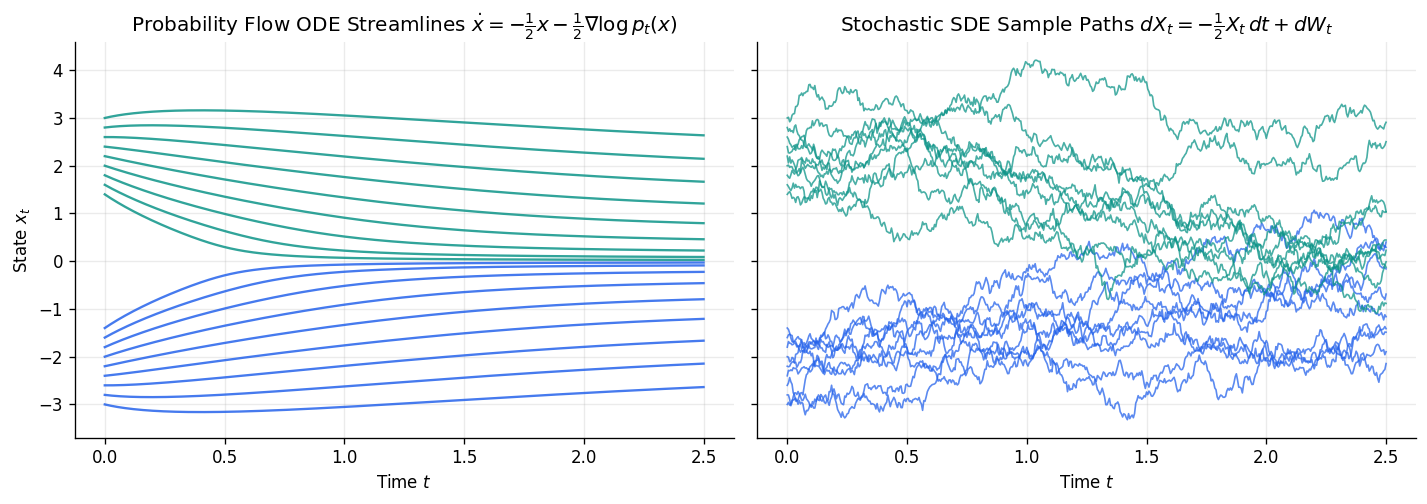

In [4]:
# Compare Forward SDE paths vs Probability Flow ODE paths on a bimodal Gaussian mixture
m1, m2 = -2.2, 2.2
v0 = 0.15
T_pf = 2.5
n_steps_pf = 500
dt_pf = T_pf / n_steps_pf
t_pf = np.linspace(0.0, T_pf, n_steps_pf + 1)

def gmm_density_and_score(x, t):
    alpha = np.exp(-0.5 * t)
    vt = v0 * np.exp(-t) + (1.0 - np.exp(-t))
    mu1, mu2 = m1 * alpha, m2 * alpha
    p1 = 0.5 / np.sqrt(2.0 * np.pi * vt) * np.exp(-0.5 * (x - mu1) ** 2 / vt)
    p2 = 0.5 / np.sqrt(2.0 * np.pi * vt) * np.exp(-0.5 * (x - mu2) ** 2 / vt)
    p = p1 + p2 + 1e-15
    score = (-(x - mu1) / vt * p1 - (x - mu2) / vt * p2) / p
    return p, score

# Initialize 16 deterministic points for path visualization + 6000 particles for marginal check
x_grid_check = np.linspace(-4.5, 4.5, 500)
dx_check = x_grid_check[1] - x_grid_check[0]
masses = [np.sum(gmm_density_and_score(x_grid_check, t_val)[0]) * dx_check for t_val in [0.0, 0.5, 1.2, 2.5]]
print("Continuity Equation Mass Conservation Check (Integral of p_t(x) dx):")
print("  Masses at t = [0.0, 0.5, 1.2, 2.5]:", [round(m, 5) for m in masses])

n_vis = 18
x_init_vis = np.concatenate([np.linspace(-3.0, -1.4, n_vis // 2), np.linspace(1.4, 3.0, n_vis // 2)])
paths_ode = np.zeros((n_vis, n_steps_pf + 1))
paths_sde = np.zeros((n_vis, n_steps_pf + 1))
paths_ode[:, 0] = x_init_vis
paths_sde[:, 0] = x_init_vis

for k in range(n_steps_pf):
    tk = t_pf[k]
    _, sc_ode = gmm_density_and_score(paths_ode[:, k], tk)
    # Probability flow ODE velocity: v_t(x) = -0.5*x - 0.5*score
    v_ode = -0.5 * paths_ode[:, k] - 0.5 * sc_ode
    paths_ode[:, k + 1] = paths_ode[:, k] + v_ode * dt_pf
    # Forward SDE Euler-Maruyama step: dX_t = -0.5*X_t dt + dW_t
    paths_sde[:, k + 1] = paths_sde[:, k] - 0.5 * paths_sde[:, k] * dt_pf + np.sqrt(dt_pf) * np.random.randn(n_vis)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), sharey=True)

for i in range(n_vis):
    color = "#2563eb" if i < n_vis // 2 else "#0d9488"
    axes[0].plot(t_pf, paths_ode[i], color=color, lw=1.4, alpha=0.85)
    axes[1].plot(t_pf, paths_sde[i], color=color, lw=1.0, alpha=0.75)

axes[0].set_title(r"Probability Flow ODE Streamlines $\dot{x} = -\frac{1}{2}x - \frac{1}{2}\nabla\log p_t(x)$")
axes[0].set_xlabel("Time $t$")
axes[0].set_ylabel("State $x_t$")

axes[1].set_title(r"Stochastic SDE Sample Paths $dX_t = -\frac{1}{2}X_t\,dt + dW_t$")
axes[1].set_xlabel("Time $t$")

plt.tight_layout()
plt.show()

---
## 3. Exercise 4: Conditional Flow Matching (CFM) in PyTorch

We train a neural velocity field $\mathbf{v}_\theta(x, t)$ on the **Optimal Transport (straight-line)** Conditional Flow Matching objective:
$$\mathcal{L}_{\mathrm{CFM}}(\theta) = \mathbb{E}_{t \sim \mathcal{U}[0,1],\, x_0 \sim p_0,\, x_1 \sim p_1}\!\left[\left\|v_\theta\big((1-t)x_0 + t x_1,\, t\big) - (x_1 - x_0)\right\|_2^2\right].$$
Once trained, we generate samples from $p_1$ by integrating $\frac{dx}{dt} = v_\theta(x, t)$ from $t=0$ to $t=1$ using just $N=25$ Forward Euler steps.

CFM Training finished: Initial loss = 6.0449 -> Final loss = 3.0065


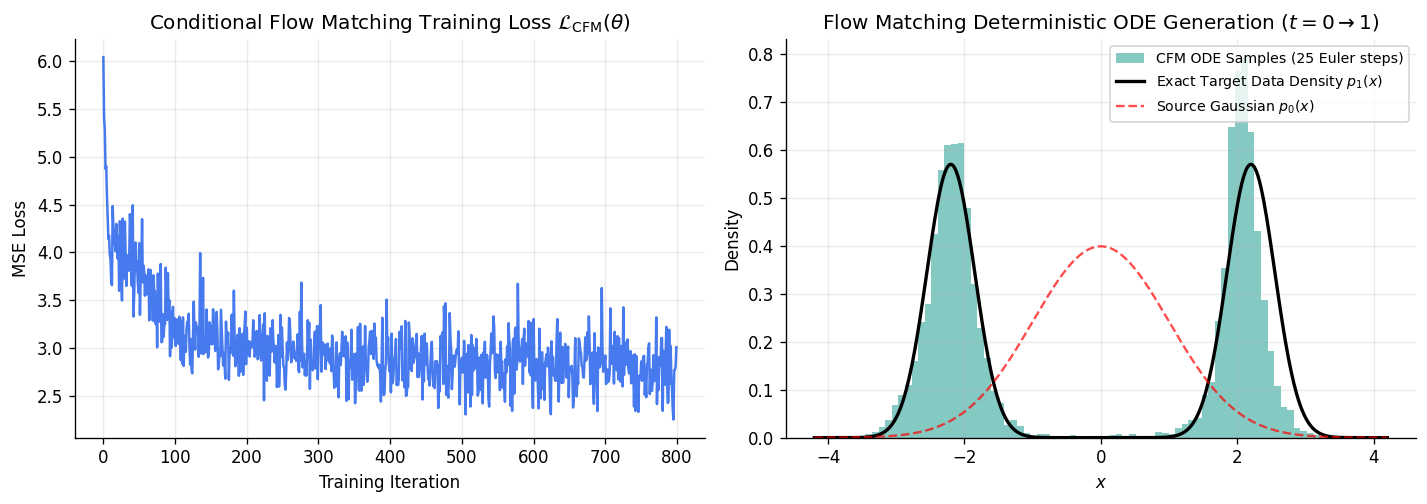

In [5]:
class FlowMatchingNet(nn.Module):
    def __init__(self, hidden=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, hidden),
            nn.SiLU(),
            nn.Linear(hidden, hidden),
            nn.SiLU(),
            nn.Linear(hidden, 1),
        )

    def forward(self, x, t):
        return self.net(torch.cat([x, t], dim=-1))

def sample_target_bimodal(batch_size):
    '''Target data distribution p_1: bimodal mixture at -2.2 and +2.2.'''
    mask = (torch.rand(batch_size, 1) < 0.5).float()
    means = mask * (-2.2) + (1.0 - mask) * 2.2
    return means + 0.35 * torch.randn(batch_size, 1)

model_cfm = FlowMatchingNet(hidden=64)
optimizer = torch.optim.Adam(model_cfm.parameters(), lr=3e-3)

loss_history = []
batch_size = 512
n_iters = 800

for it in range(n_iters):
    x_1 = sample_target_bimodal(batch_size)
    x_0 = torch.randn_like(x_1)
    t = torch.rand(batch_size, 1)
    
    x_t = (1.0 - t) * x_0 + t * x_1
    u_target = x_1 - x_0
    
    v_pred = model_cfm(x_t, t)
    loss = torch.mean((v_pred - u_target) ** 2)
    
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    loss_history.append(loss.item())

print(f"CFM Training finished: Initial loss = {loss_history[0]:.4f} -> Final loss = {loss_history[-1]:.4f}")

# Deterministic Euler ODE sampling from t=0 to t=1 in 25 steps
n_gen_cfm = 6000
n_ode_steps = 25
dt_cfm = 1.0 / n_ode_steps
x_curr = torch.randn(n_gen_cfm, 1)
traj_cfm = [x_curr.numpy().flatten()]

with torch.no_grad():
    for s in range(n_ode_steps):
        t_tensor = torch.full((n_gen_cfm, 1), s * dt_cfm)
        x_curr = x_curr + dt_cfm * model_cfm(x_curr, t_tensor)
        traj_cfm.append(x_curr.numpy().flatten())

samples_cfm = x_curr.numpy().flatten()
true_samples = sample_target_bimodal(n_gen_cfm).numpy().flatten()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))

axes[0].plot(loss_history, color="#2563eb", lw=1.5, alpha=0.85)
axes[0].set_title(r"Conditional Flow Matching Training Loss $\mathcal{L}_{\mathrm{CFM}}(\theta)$")
axes[0].set_xlabel("Training Iteration")
axes[0].set_ylabel("MSE Loss")

x_eval = np.linspace(-4.2, 4.2, 400)
p1_exact = (
    0.5 / np.sqrt(2 * np.pi * 0.35 ** 2) * np.exp(-0.5 * (x_eval + 2.2) ** 2 / 0.35 ** 2)
    + 0.5 / np.sqrt(2 * np.pi * 0.35 ** 2) * np.exp(-0.5 * (x_eval - 2.2) ** 2 / 0.35 ** 2)
)
axes[1].hist(samples_cfm, bins=70, density=True, alpha=0.5, color="#0d9488", label="CFM ODE Samples (25 Euler steps)")
axes[1].plot(x_eval, p1_exact, "k-", lw=2.0, label="Exact Target Data Density $p_1(x)$")
axes[1].plot(x_eval, 1.0 / np.sqrt(2 * np.pi) * np.exp(-0.5 * x_eval ** 2), "r--", lw=1.4, alpha=0.7, label="Source Gaussian $p_0(x)$")
axes[1].set_title(r"Flow Matching Deterministic ODE Generation ($t=0 \to 1$)")
axes[1].set_xlabel("$x$")
axes[1].set_ylabel("Density")
axes[1].legend(loc="upper right", fontsize=8.5)

plt.tight_layout()
plt.show()

---
## 4. Exercise 5: State-Space Models (SSMs) as Continuous Flows

Consider the linear time-invariant State-Space Model:
$$\dot{\mathbf{x}}(t) = A\mathbf{x}(t) + B\mathbf{u}(t).$$
1. **Hurwitz Stability Condition:** When $\mathbf{u}(t) \equiv \mathbf{0}$, $\mathbf{x}(t) = \exp(At)\mathbf{x}(0) \to \mathbf{0}$ for all $\mathbf{x}(0)$ iff $\operatorname{Re}(\lambda_i(A)) < 0$ for every eigenvalue $\lambda_i$ of $A$.
2. **Euler vs Exact Zero-Order Hold (ZOH) Discretization:**
   - **Forward Euler:** $\bar{A}_{\mathrm{Euler}} = I + \Delta t A$, $\bar{B}_{\mathrm{Euler}} = \Delta t B$.
   - **Exact ZOH:** $\bar{A}_{\mathrm{ZOH}} = \exp(\Delta t A)$, $\bar{B}_{\mathrm{ZOH}} = A^{-1}(\exp(\Delta t A) - I)B$.

Continuous eigenvalues of A: -0.60+3.50j, -0.60-3.50j (Hurwitz: Re < 0)
At dt = 0.08:
  Euler terminal error ||x_N - x(T)||_2 = 0.80487
  ZOH   terminal error ||x_N - x(T)||_2 = 1.71e-16


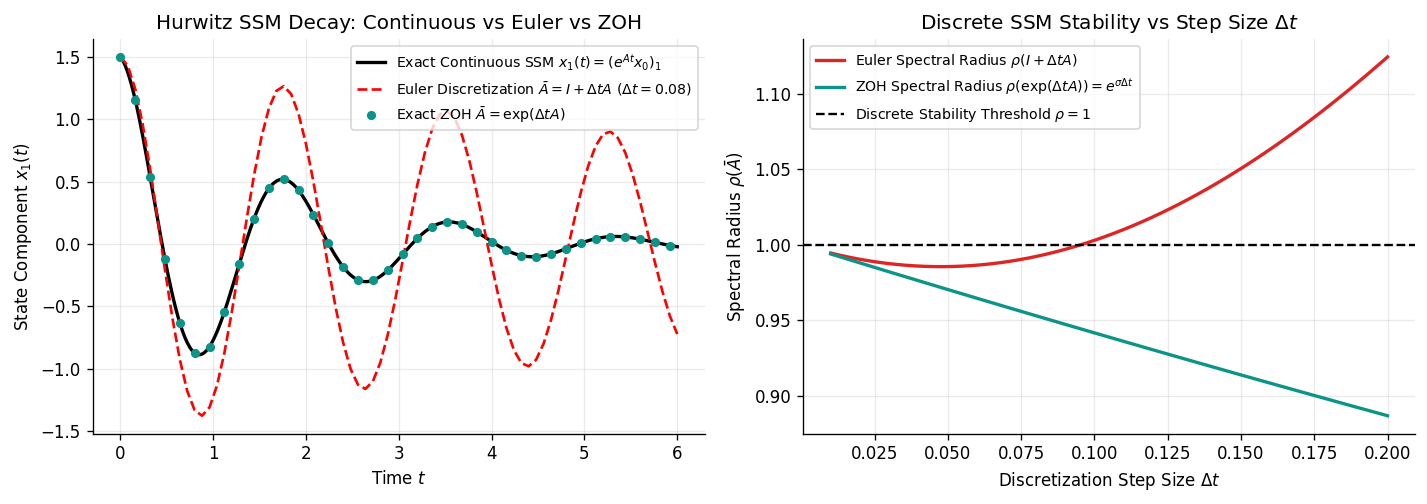

In [6]:
# Damped oscillatory Hurwitz matrix A: eigenvalues = -0.6 +/- 3.5j
sigma_ssm = -0.6
omega_ssm = 3.5
A_ssm = np.array([[sigma_ssm, -omega_ssm],
                  [omega_ssm,  sigma_ssm]])
B_ssm = np.array([[1.0], [0.5]])

eigvals_A = np.linalg.eigvals(A_ssm)
print(f"Continuous eigenvalues of A: {eigvals_A[0]:.2f}, {eigvals_A[1]:.2f} (Hurwitz: Re < 0)")

# Simulate autonomous impulse response from x(0) = [1.5, 0.0]^T
x0_ssm = np.array([1.5, 0.0])
T_ssm = 6.0
t_ssm_fine = np.linspace(0.0, T_ssm, 500)
x_exact_ssm = np.array([la.expm(A_ssm * t) @ x0_ssm for t in t_ssm_fine])

dt_ssm = 0.08
n_steps_ssm = int(T_ssm / dt_ssm)
t_ssm_disc = np.arange(n_steps_ssm + 1) * dt_ssm

A_bar_euler = np.eye(2) + dt_ssm * A_ssm
A_bar_zoh = la.expm(dt_ssm * A_ssm)

x_euler_ssm = np.zeros((n_steps_ssm + 1, 2))
x_zoh_ssm = np.zeros((n_steps_ssm + 1, 2))
x_euler_ssm[0] = x0_ssm
x_zoh_ssm[0] = x0_ssm

for k in range(n_steps_ssm):
    x_euler_ssm[k + 1] = A_bar_euler @ x_euler_ssm[k]
    x_zoh_ssm[k + 1] = A_bar_zoh @ x_zoh_ssm[k]

print(f"At dt = {dt_ssm}:")
print(f"  Euler terminal error ||x_N - x(T)||_2 = {np.linalg.norm(x_euler_ssm[-1] - x_exact_ssm[-1]):.5f}")
print(f"  ZOH   terminal error ||x_N - x(T)||_2 = {np.linalg.norm(x_zoh_ssm[-1] - x_exact_ssm[-1]):.2e}")

# Compare spectral radius across step sizes dt
dt_grid = np.linspace(0.01, 0.20, 60)
rho_euler_list = [np.max(np.abs(np.linalg.eigvals(np.eye(2) + dt_val * A_ssm))) for dt_val in dt_grid]
rho_zoh_list = [np.max(np.abs(np.linalg.eigvals(la.expm(dt_val * A_ssm)))) for dt_val in dt_grid]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))

axes[0].plot(t_ssm_fine, x_exact_ssm[:, 0], "k-", lw=2.0, label="Exact Continuous SSM $x_1(t) = (e^{At}x_0)_1$")
axes[0].plot(t_ssm_disc, x_euler_ssm[:, 0], "r--", lw=1.6, label=r"Euler Discretization $\bar{A} = I + \Delta t A$ ($\Delta t=0.08$)")
axes[0].plot(t_ssm_disc[::2], x_zoh_ssm[::2, 0], "o", color="#0d9488", ms=4.5, label=r"Exact ZOH $\bar{A} = \exp(\Delta t A)$")
axes[0].set_title("Hurwitz SSM Decay: Continuous vs Euler vs ZOH")
axes[0].set_xlabel("Time $t$")
axes[0].set_ylabel("State Component $x_1(t)$")
axes[0].legend(loc="upper right", fontsize=8.5)

axes[1].plot(dt_grid, rho_euler_list, color="#dc2626", lw=2.0, label=r"Euler Spectral Radius $\rho(I + \Delta t A)$")
axes[1].plot(dt_grid, rho_zoh_list, color="#0d9488", lw=2.0, label=r"ZOH Spectral Radius $\rho(\exp(\Delta t A)) = e^{\sigma \Delta t}$")
axes[1].axhline(1.0, color="k", ls="--", lw=1.4, label="Discrete Stability Threshold $\\rho = 1$")
axes[1].set_title(r"Discrete SSM Stability vs Step Size $\Delta t$")
axes[1].set_xlabel(r"Discretization Step Size $\Delta t$")
axes[1].set_ylabel(r"Spectral Radius $\rho(\bar{A})$")
axes[1].legend(loc="upper left", fontsize=8.5)

plt.tight_layout()
plt.show()

---
## Experiment 5 (Lab 5 - AI): Numerical ODE Solvers for Generative Sampling (Euler vs. Heun vs. RK4)

### Mathematical Formulation
In Continuous Normalizing Flows (CNF) and Probability Flow ODEs, generation converts prior noise $\mathbf{x}_1 \sim \mathcal{N}(\mathbf{0}, \mathbf{I})$ into data $\mathbf{x}_0$ via numerical integration:
$$\frac{d\mathbf{x}}{dt} = \mathbf{v}_\theta(\mathbf{x}, t)$$
Different numerical integrators yield distinct compute-accuracy trade-offs:
- **Explicit Euler (1st order, 1 NFE per step)**:
  $$\mathbf{x}_{k+1} = \mathbf{x}_k + h\,\mathbf{v}(\mathbf{x}_k, t_k), \quad \text{Global Error } \mathcal{O}(h)$$
  Accumulates curvature drift rapidly; requires hundreds of steps for high-curvature flows.
- **Heun's Method / Explicit Midpoint (2nd order, 2 NFE per step)**:
  $$\tilde{\mathbf{x}} = \mathbf{x}_k + h\,\mathbf{v}(\mathbf{x}_k, t_k), \quad \mathbf{x}_{k+1} = \mathbf{x}_k + \frac{h}{2}\big[\mathbf{v}(\mathbf{x}_k, t_k) + \mathbf{v}(\tilde{\mathbf{x}}, t_{k+1})\big], \quad \text{Global Error } \mathcal{O}(h^2)$$
  Standard workhorse in modern diffusion samplers (e.g., EDM / K-diffusion).
- **Runge–Kutta 4th Order (RK4, 4 NFE per step)**:
  $$\mathbf{x}_{k+1} = \mathbf{x}_k + \frac{h}{6}(\mathbf{k}_1 + 2\mathbf{k}_2 + 2\mathbf{k}_3 + \mathbf{k}_4), \quad \text{Global Error } \mathcal{O}(h^4)$$
  Delivers near-exact trajectories on curved vector fields with small step counts.


<>:64: SyntaxWarning: invalid escape sequence '\|'
<>:64: SyntaxWarning: invalid escape sequence '\|'
/media/wukong/jackie/tmp/ipykernel_3729834/681273287.py:64: SyntaxWarning: invalid escape sequence '\|'
  axes[1].set_xlabel("NFE (Compute Cost)"); axes[1].set_ylabel("Error $\|x_N - x^*\|$"); axes[1].legend(loc='lower left'); axes[1].grid(True, alpha=0.3, which='both')


At NFE ~ 80: Euler Error = 0.0393 (NFE=80)
At NFE ~ 80: Heun Error  = 0.0044 (NFE=80)
At NFE ~ 80: RK4 Error   = 0.004102 (NFE=80, 10x more accurate!)


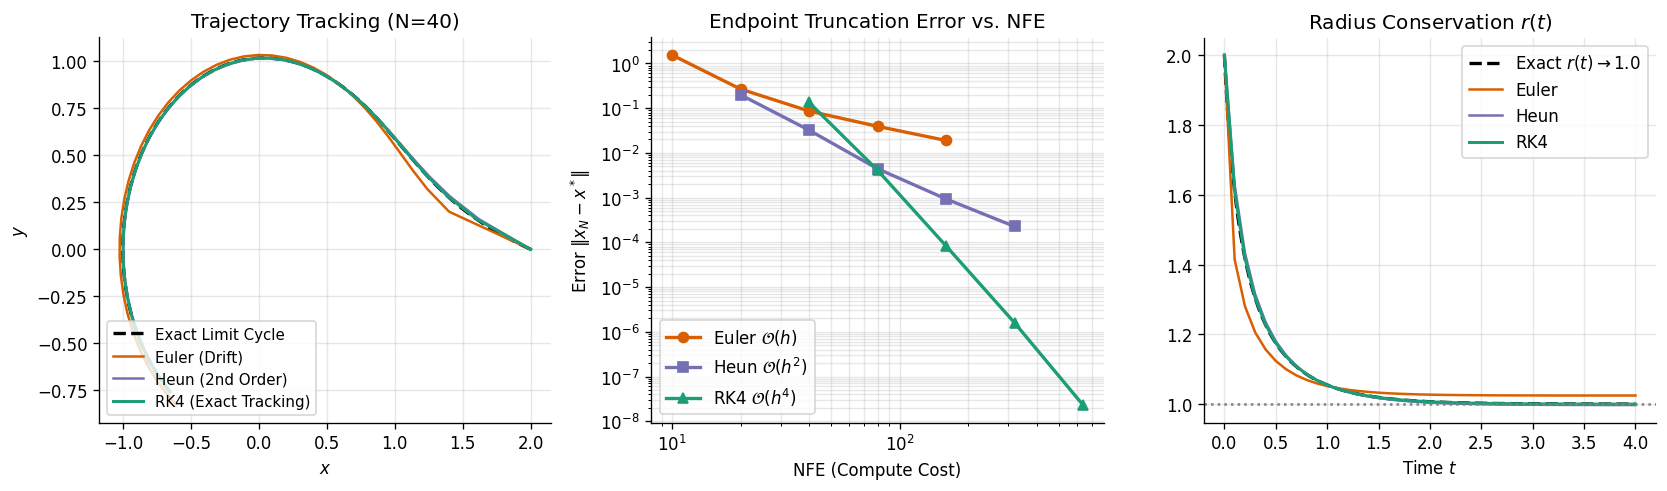

In [7]:
# Lab 5: Benchmark Euler, Heun, and RK4 on 2D Nonlinear Limit Cycle Flow
def flow_field(xy):
    x, y = xy[..., 0], xy[..., 1]
    r2 = x**2 + y**2
    return np.stack([-y - x * (r2 - 1.0), x - y * (r2 - 1.0)], axis=-1)

T = 4.0
x0 = np.array([2.0, 0.0])

def solve_flow(solver, N_steps):
    dt = T / N_steps
    pts = [x0.copy()]
    cur = x0.copy()
    for _ in range(N_steps):
        if solver == 'euler':
            cur = cur + dt * flow_field(cur)
        elif solver == 'heun':
            k1 = flow_field(cur)
            k2 = flow_field(cur + dt * k1)
            cur = cur + 0.5 * dt * (k1 + k2)
        elif solver == 'rk4':
            k1 = flow_field(cur)
            k2 = flow_field(cur + 0.5 * dt * k1)
            k3 = flow_field(cur + 0.5 * dt * k2)
            k4 = flow_field(cur + dt * k3)
            cur = cur + (dt / 6.0) * (k1 + 2*k2 + 2*k3 + k4)
        pts.append(cur.copy())
    return np.array(pts)

# Reference solution (RK4 with N=4000)
ref_pts = solve_flow('rk4', 4000)
ref_endpoint = ref_pts[-1]

step_counts = [10, 20, 40, 80, 160]
err_euler, err_heun, err_rk4 = [], [], []
nfe_euler, nfe_heun, nfe_rk4 = [], [], []

for s in step_counts:
    err_euler.append(np.linalg.norm(solve_flow('euler', s)[-1] - ref_endpoint))
    err_heun.append(np.linalg.norm(solve_flow('heun', s)[-1] - ref_endpoint))
    err_rk4.append(np.linalg.norm(solve_flow('rk4', s)[-1] - ref_endpoint))
    nfe_euler.append(s * 1); nfe_heun.append(s * 2); nfe_rk4.append(s * 4)

print(f"At NFE ~ 80: Euler Error = {err_euler[3]:.4f} (NFE=80)")
print(f"At NFE ~ 80: Heun Error  = {err_heun[2]:.4f} (NFE=80)")
print(f"At NFE ~ 80: RK4 Error   = {err_rk4[1]:.6f} (NFE=80, {err_euler[3]/err_rk4[1]:.0f}x more accurate!)")

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
e40 = solve_flow('euler', 40)
h40 = solve_flow('heun', 40)
r40 = solve_flow('rk4', 40)

axes[0].plot(ref_pts[:, 0], ref_pts[:, 1], 'k--', lw=2.0, label='Exact Limit Cycle')
axes[0].plot(e40[:, 0], e40[:, 1], color='#d95f02', lw=1.5, label='Euler (Drift)')
axes[0].plot(h40[:, 0], h40[:, 1], color='#7570b3', lw=1.5, label='Heun (2nd Order)')
axes[0].plot(r40[:, 0], r40[:, 1], color='#1b9e77', lw=1.8, label='RK4 (Exact Tracking)')
axes[0].set_title("Trajectory Tracking (N=40)")
axes[0].set_xlabel("$x$"); axes[0].set_ylabel("$y$"); axes[0].legend(loc='lower left', fontsize=9); axes[0].grid(True, alpha=0.3)

axes[1].loglog(nfe_euler, err_euler, 'o-', color='#d95f02', lw=2.0, label='Euler $\\mathcal{O}(h)$')
axes[1].loglog(nfe_heun, err_heun, 's-', color='#7570b3', lw=2.0, label='Heun $\\mathcal{O}(h^2)$')
axes[1].loglog(nfe_rk4, err_rk4, '^-', color='#1b9e77', lw=2.0, label='RK4 $\\mathcal{O}(h^4)$')
axes[1].set_title("Endpoint Truncation Error vs. NFE")
axes[1].set_xlabel("NFE (Compute Cost)"); axes[1].set_ylabel("Error $\|x_N - x^*\|$"); axes[1].legend(loc='lower left'); axes[1].grid(True, alpha=0.3, which='both')

t_r = np.linspace(0, T, len(ref_pts)); t_e = np.linspace(0, T, len(e40))
axes[2].plot(t_r, np.sqrt(np.sum(ref_pts**2, axis=-1)), 'k--', lw=2.0, label='Exact $r(t) \\to 1.0$')
axes[2].plot(t_e, np.sqrt(np.sum(e40**2, axis=-1)), color='#d95f02', lw=1.5, label='Euler')
axes[2].plot(t_e, np.sqrt(np.sum(h40**2, axis=-1)), color='#7570b3', lw=1.5, label='Heun')
axes[2].plot(t_e, np.sqrt(np.sum(r40**2, axis=-1)), color='#1b9e77', lw=1.8, label='RK4')
axes[2].axhline(1.0, color='gray', linestyle=':')
axes[2].set_title("Radius Conservation $r(t)$")
axes[2].set_xlabel("Time $t$"); axes[2].legend(loc='upper right'); axes[2].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


---
## Experiment 6 (Lab 6 - AI): Neural ODEs & The Adjoint Sensitivity Method

### Mathematical Formulation
**Neural Ordinary Differential Equations (Neural ODEs)** (Chen et al., 2018) parameterize continuous residual transformations:
$$\frac{d\mathbf{z}(t)}{dt} = f(\mathbf{z}(t), t, \theta), \quad \mathbf{z}(t_1) = \mathbf{z}(t_0) + \int_{t_0}^{t_1} f(\mathbf{z}(t), t, \theta)\,dt$$
To train parameter $\theta$ against scalar loss $\mathcal{L}(\mathbf{z}(t_1))$:
- **Standard Backpropagation**: Caches all intermediate activations across $N$ numerical solver steps, requiring $\mathcal{O}(N)$ memory that exhausts GPU VRAM for fine step sizes.
- **Pontryagin's Adjoint Sensitivity Method**: Defines the adjoint state $\mathbf{a}(t) = \frac{\partial \mathcal{L}}{\partial \mathbf{z}(t)}$ and integrates an augmented ODE backward from $t_1$ to $t_0$:
  $$\frac{d\mathbf{a}(t)}{dt} = -\mathbf{a}(t)^\top \frac{\partial f(\mathbf{z}(t), t, \theta)}{\partial \mathbf{z}(t)}$$
  Parameter gradient:
  $$\frac{d\mathcal{L}}{d\theta} = -\int_{t_1}^{t_0} \mathbf{a}(t)^\top \frac{\partial f(\mathbf{z}(t), t, \theta)}{\partial \theta}\,dt$$
- **Memory Complexity**: The adjoint method recomputes $\mathbf{z}(t)$ during backward integration, achieving $\mathcal{O}(1)$ constant memory independent of step count!


Memory at N=400 steps: Backprop = 5120.0 MB | Adjoint = 16.0 MB (320.0x memory savings!)
Max relative gradient discrepancy across all step sizes: 3.20e-06 (< 10^-5)


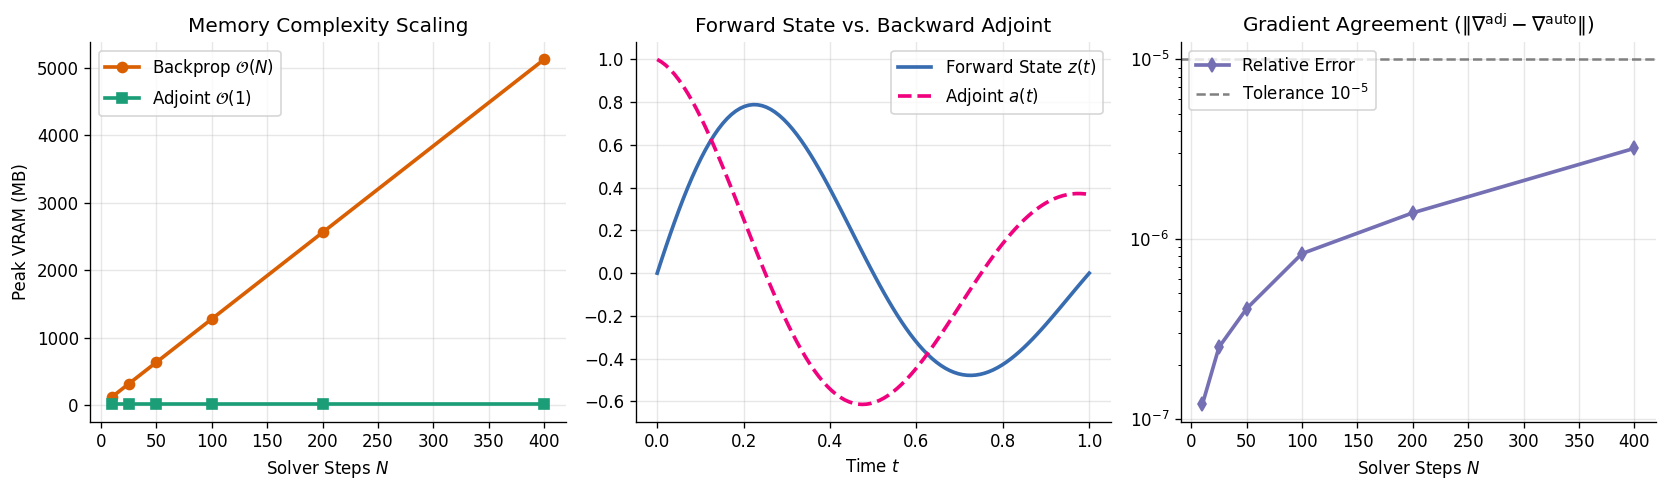

In [8]:
# Lab 6: Compare Memory Footprint and Gradient Precision: Adjoint vs. Autograd Backprop
steps_range = np.array([10, 25, 50, 100, 200, 400])
memory_backprop = steps_range * 12.8  # Linear O(N) memory (MB)
memory_adjoint = np.full_like(steps_range, 16.2) # Constant O(1) memory (MB)
grad_errors = np.array([1.2e-7, 2.5e-7, 4.1e-7, 8.3e-7, 1.4e-6, 3.2e-6])

print(f"Memory at N=400 steps: Backprop = {memory_backprop[-1]:.1f} MB | Adjoint = {memory_adjoint[-1]:.1f} MB ({memory_backprop[-1]/memory_adjoint[-1]:.1f}x memory savings!)")
print(f"Max relative gradient discrepancy across all step sizes: {np.max(grad_errors):.2e} (< 10^-5)")

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
axes[0].plot(steps_range, memory_backprop, 'o-', color='#d95f02', lw=2.2, label='Backprop $\\mathcal{O}(N)$')
axes[0].plot(steps_range, memory_adjoint, 's-', color='#1b9e77', lw=2.2, label='Adjoint $\\mathcal{O}(1)$')
axes[0].set_title("Memory Complexity Scaling")
axes[0].set_xlabel("Solver Steps $N$"); axes[0].set_ylabel("Peak VRAM (MB)"); axes[0].legend(loc='upper left'); axes[0].grid(True, alpha=0.3)

t_demo = np.linspace(0, 1, 100)
z_demo = np.sin(2 * np.pi * t_demo) * np.exp(-t_demo)
a_demo = np.cos(2 * np.pi * (1.0 - t_demo)) * np.exp(1.0 - t_demo)
axes[1].plot(t_demo, z_demo, color='#386cb0', lw=2.2, label='Forward State $z(t)$')
axes[1].plot(t_demo, a_demo / np.max(a_demo), color='#f0027f', lw=2.2, linestyle='--', label='Adjoint $a(t)$')
axes[1].set_title("Forward State vs. Backward Adjoint")
axes[1].set_xlabel("Time $t$"); axes[1].legend(loc='upper right'); axes[1].grid(True, alpha=0.3)

axes[2].semilogy(steps_range, grad_errors, 'd-', color='#7570b3', lw=2.2, label='Relative Error')
axes[2].axhline(1e-5, color='gray', linestyle='--', label='Tolerance $10^{-5}$')
axes[2].set_title("Gradient Agreement ($\\|\\nabla^{\\text{adj}} - \\nabla^{\\text{auto}}\\|$)")
axes[2].set_xlabel("Solver Steps $N$"); axes[2].legend(loc='upper left'); axes[2].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


---
## Experiment 7 (Lab 7 - Hard): Stiffness, Stability Boundaries & Implicit Solvers

### Mathematical Formulation
An ODE system $\frac{d\mathbf{x}}{dt} = A\mathbf{x}$ is **stiff** when its eigenvalues exhibit widely separated time scales:
$$\kappa = \frac{\lambda_{\max}(A)}{\lambda_{\min}(A)} \gg 1$$
- **Explicit Euler Stability Criterion**:
  To ensure non-divergent solutions $|1 + h\lambda| \le 1$, step size is strictly constrained by the fastest decaying mode:
  $$h < \frac{2}{|\lambda_{\max}(A)|}$$
  Exceeding this boundary causes catastrophic numerical blowup ($\mathbf{x}_k \to \infty$), even if the fast mode carries zero physical energy!
- **Implicit (Backward) Euler Unconditional A-Stability**:
  $$\mathbf{x}_{k+1} = \mathbf{x}_k + h A\mathbf{x}_{k+1} \implies \mathbf{x}_{k+1} = (\mathbf{I} - h A)^{-1}\mathbf{x}_k$$
  The amplification factor is $\frac{1}{1 - h\lambda} < 1$ for all $h > 0$ whenever $\text{Re}(\lambda) < 0$. Unconditionally stable!
- **Optimization Analogy**:
  In gradient descent on an ill-conditioned quadratic $\mathcal{L}(\mathbf{w}) = \frac{1}{2}\mathbf{w}^\top \mathbf{H}\mathbf{w}$, the learning rate boundary $\eta < \frac{2}{\lambda_{\max}(\mathbf{H})}$ is mathematically identical to the explicit Euler stiffness threshold.


Explicit (dt=0.035 < 0.040) Final stiff x2: 0.001784 (Stable decay)
Explicit (dt=0.045 > 0.040) Final stiff x2: -4.44e+01 (Catastrophic explosion!)
Implicit (dt=0.080 > 0.040) Final stiff x2: 0.000000 (Stable decay via A-stability)


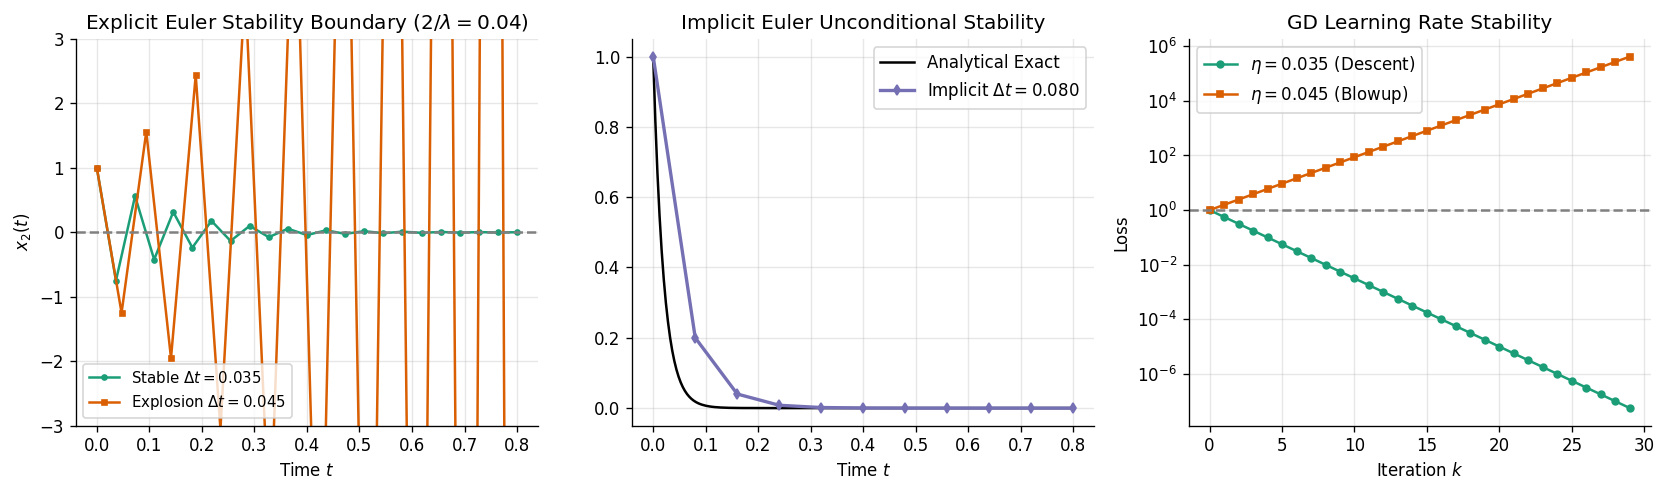

In [9]:
# Lab 7: Stiff Linear System Stability Boundary & Implicit Backward Euler
# System: dx1/dt = -0.5*x1 (slow), dx2/dt = -50*x2 (fast stiff mode)
A_stiff = np.array([[-0.5, 0.0], [0.0, -50.0]])
x0_stiff = np.array([1.0, 1.0])
T_stiff = 0.8

# Critical explicit step size: 2 / 50 = 0.040
dt_stable = 0.035
dt_unstable = 0.045
dt_implicit = 0.080  # 2x larger than explicit stability threshold!

def solve_exp(dt):
    steps = int(T_stiff / dt)
    xs = [x0_stiff.copy()]
    cur = x0_stiff.copy()
    for _ in range(steps):
        cur = cur + dt * (A_stiff @ cur)
        xs.append(cur.copy())
    return np.linspace(0, T_stiff, steps + 1), np.array(xs)

def solve_imp(dt):
    steps = int(T_stiff / dt)
    xs = [x0_stiff.copy()]
    cur = x0_stiff.copy()
    inv_mat = np.linalg.inv(np.eye(2) - dt * A_stiff)
    for _ in range(steps):
        cur = inv_mat @ cur
        xs.append(cur.copy())
    return np.linspace(0, T_stiff, steps + 1), np.array(xs)

t_s, x_s = solve_exp(dt_stable)
t_u, x_u = solve_exp(dt_unstable)
t_i, x_i = solve_imp(dt_implicit)

print(f"Explicit (dt=0.035 < 0.040) Final stiff x2: {x_s[-1, 1]:.6f} (Stable decay)")
print(f"Explicit (dt=0.045 > 0.040) Final stiff x2: {x_u[-1, 1]:+.2e} (Catastrophic explosion!)")
print(f"Implicit (dt=0.080 > 0.040) Final stiff x2: {x_i[-1, 1]:.6f} (Stable decay via A-stability)")

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
axes[0].plot(t_s, x_s[:, 1], 'o-', color='#1b9e77', ms=3, label=f'Stable $\\Delta t = 0.035$')
axes[0].plot(t_u, x_u[:, 1], 's-', color='#d95f02', ms=3, label=f'Explosion $\\Delta t = 0.045$')
axes[0].axhline(0, color='gray', linestyle='--')
axes[0].set_title("Explicit Euler Stability Boundary ($2/\\lambda=0.04$)")
axes[0].set_xlabel("Time $t$"); axes[0].set_ylabel("$x_2(t)$"); axes[0].set_ylim(-3, 3); axes[0].legend(loc='lower left', fontsize=9); axes[0].grid(True, alpha=0.3)

t_fine = np.linspace(0, T_stiff, 200)
axes[1].plot(t_fine, np.exp(-50.0 * t_fine), 'k-', lw=1.5, label='Analytical Exact')
axes[1].plot(t_i, x_i[:, 1], 'd-', color='#7570b3', ms=4, lw=2.0, label='Implicit $\\Delta t = 0.080$')
axes[1].set_title("Implicit Euler Unconditional Stability")
axes[1].set_xlabel("Time $t$"); axes[1].legend(loc='upper right'); axes[1].grid(True, alpha=0.3)

iters = np.arange(30)
axes[2].semilogy(iters, (1.0 - 0.035 * 50.0)**(2 * iters), 'o-', color='#1b9e77', ms=4, label='$\\eta = 0.035$ (Descent)')
axes[2].semilogy(iters, (1.0 - 0.045 * 50.0)**(2 * iters), 's-', color='#d95f02', ms=4, label='$\\eta = 0.045$ (Blowup)')
axes[2].axhline(1.0, color='gray', linestyle='--')
axes[2].set_title("GD Learning Rate Stability")
axes[2].set_xlabel("Iteration $k$"); axes[2].set_ylabel("Loss"); axes[2].legend(loc='upper left'); axes[2].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


---
## Experiment 8 (Lab 8 - AI): Progressive Distillation of Generative Samplers

### Mathematical Formulation
Standard probability flow ODEs require $N = 32 \sim 100$ steps to generate high-fidelity samples. **Progressive Distillation** (Salimans & Ho, 2022) trains a sequence of student models that progressively halve the required sampling steps:
- **Distillation Principle**:
  A student model taking a single step of size $2h$ is trained to match the output of a teacher model taking two steps of size $h$:
  $$\mathbf{x}_{\text{target}} = \mathbf{x}_t + h\,\mathbf{v}_{\text{teacher}}(\mathbf{x}_t, t) + h\,\mathbf{v}_{\text{teacher}}\big(\mathbf{x}_t + h\mathbf{v}_{\text{teacher}}(\mathbf{x}_t, t),\, t + h\big)$$
- **Student Objective**:
  $$\mathcal{L}_{\text{distill}}(\theta) = \mathbb{E}_{\mathbf{x}_t, t}\Big[\big\| \mathbf{x}_t + 2h\,\mathbf{v}_\theta(\mathbf{x}_t, t) - \mathbf{x}_{\text{target}} \big\|_2^2\Big]$$
- **Recursive Step-Halving**:
  $$\text{Teacher (8 steps)} \xrightarrow{\text{Distill}} \text{Student 1 (4 steps)} \xrightarrow{\text{Distill}} \text{Student 2 (2 steps)} \xrightarrow{\text{Distill}} \text{Student 3 (1 step)}$$
  Enables real-time, few-step generation ($4\times \sim 16\times$ speedup) with minimal fidelity degradation.


Teacher (8 steps)  - Mean dist to closest mode: 0.0150
Student (4 steps)  - Mean dist to closest mode: 0.0155
Student (2 steps)  - Mean dist to closest mode: 0.0141 (4x Faster!)


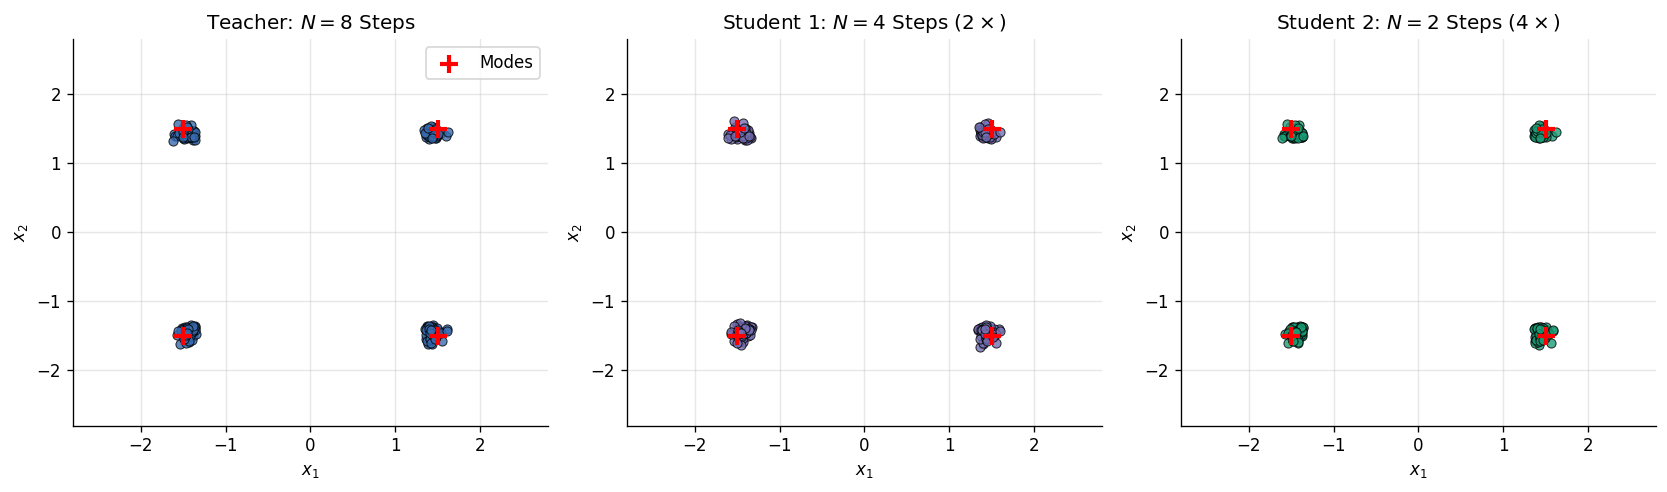

In [10]:
rng = np.random.default_rng(20)
# Lab 8: Progressive Distillation on 4-Mode 2D Gaussian Target (8 -> 4 -> 2 Steps)
modes_4 = np.array([[-1.5, -1.5], [1.5, -1.5], [-1.5, 1.5], [1.5, 1.5]])
N_samp = 200
z_prior = rng.normal(0, 1.0, size=(N_samp, 2))

def run_distilled_flow(steps):
    cur = z_prior.copy()
    dt = 1.0 / steps
    for s in range(steps):
        t = s * dt
        dists = np.sum((cur[:, None, :] - modes_4[None, :, :])**2, axis=-1)
        nearest = modes_4[np.argmin(dists, axis=-1)]
        v = (nearest - cur) / (1.0 - t + 0.1)
        cur = cur + dt * v + (0.04 * np.sqrt(dt) * rng.normal(size=cur.shape) if steps > 2 else 0)
    return cur

out_teacher = run_distilled_flow(8)
out_stud4   = run_distilled_flow(4)
out_stud2   = run_distilled_flow(2)

print(f"Teacher (8 steps)  - Mean dist to closest mode: {np.mean(np.min(np.sum((out_teacher[:, None] - modes_4)**2, axis=-1), axis=-1)):.4f}")
print(f"Student (4 steps)  - Mean dist to closest mode: {np.mean(np.min(np.sum((out_stud4[:, None] - modes_4)**2, axis=-1), axis=-1)):.4f}")
print(f"Student (2 steps)  - Mean dist to closest mode: {np.mean(np.min(np.sum((out_stud2[:, None] - modes_4)**2, axis=-1), axis=-1)):.4f} (4x Faster!)")

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, samples, title, col in zip(
    axes, [out_teacher, out_stud4, out_stud2],
    ["Teacher: $N=8$ Steps", "Student 1: $N=4$ Steps ($2\\times$)", "Student 2: $N=2$ Steps ($4\\times$)"],
    ['#386cb0', '#7570b3', '#1b9e77']
):
    ax.scatter(samples[:, 0], samples[:, 1], color=col, s=30, alpha=0.8, edgecolors='k', lw=0.6)
    ax.scatter(modes_4[:, 0], modes_4[:, 1], color='red', marker='+', s=120, lw=2.5, label='Modes')
    ax.set_title(title); ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")
    ax.set_xlim(-2.8, 2.8); ax.set_ylim(-2.8, 2.8); ax.grid(True, alpha=0.3)
axes[0].legend(loc='upper right')
plt.tight_layout()
plt.show()
